# LRS-2x — the evidence, charted

Hold SSO (2x S&P 500) while SPY is above its 200-day average, SGOV (T-bills) below.
Rule and verdicts: `docs/METHODOLOGY-2026-11.md`. This notebook only draws what
`scripts/lrs_check.py`, `scripts/lrs_1515_check.py` and `scripts/lrs_crosscheck.py`
compute — no new trials. Run All after **Restart Kernel**.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..")
sys.path[:0] = [ROOT, os.path.join(ROOT, "scripts")]
import datetime as dt
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import quantstats as qs
import lrs_check as L, lrs_1515_check as M, lrs_crosscheck as X
from rhengine.alpha import lrs
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": .3})
df = L.load()
s2 = L.strategies(df, lag=2)   # repo convention: trade at the next close
s1 = L.strategies(df, lag=1)   # the paper's timing
print(df.index[0].date(), "->", df.index[-1].date())

1926-07-01 -> 2026-09-30


## 1. Performance tables (lag 2), full sample and after publication

In [2]:
def table(s, lo, hi):
    w = s.loc[lo:hi]
    rows = {c: L.perf(w[c], w.rf, w.market) for c in ("market", "bh2x", "lrs1x", "lrs2x")}
    t = pd.DataFrame(rows).T[["cagr", "vol", "sharpe", "maxdd", "alpha", "alpha_t", "beta"]]
    return t.style.format({"cagr": "{:.2%}", "vol": "{:.1%}", "sharpe": "{:.2f}", "maxdd": "{:.1%}",
                           "alpha": "{:.2%}", "alpha_t": "{:.2f}", "beta": "{:.2f}"})
display(table(s2, "1927", "2026-09-30"))
display(table(s2, "2016-07-01", "2026-09-30"))

,cagr,vol,sharpe,maxdd,alpha,alpha_t,beta
market,10.20%,17.5%,0.46,-84.1%,-0.00%,-1.91,1.00
bh2x,12.52%,35.0%,0.42,-98.4%,-1.16%,-5.00,2.02
lrs1x,10.01%,11.6%,0.61,-41.1%,3.31%,3.38,0.47
lrs2x,15.19%,23.2%,0.59,-68.3%,6.36%,3.30,0.93


,cagr,vol,sharpe,maxdd,alpha,alpha_t,beta
market,15.31%,18.4%,0.74,-34.2%,0.00%,0.44,1.00
bh2x,23.70%,36.7%,0.70,-59.7%,-2.54%,-4.00,2.04
lrs1x,11.72%,12.2%,0.77,-23.0%,2.24%,0.87,0.55
lrs2x,19.30%,24.4%,0.75,-42.1%,3.71%,0.74,1.09


## 2. Growth of $1 (log scale) — shaded = out of the market (T-bills)

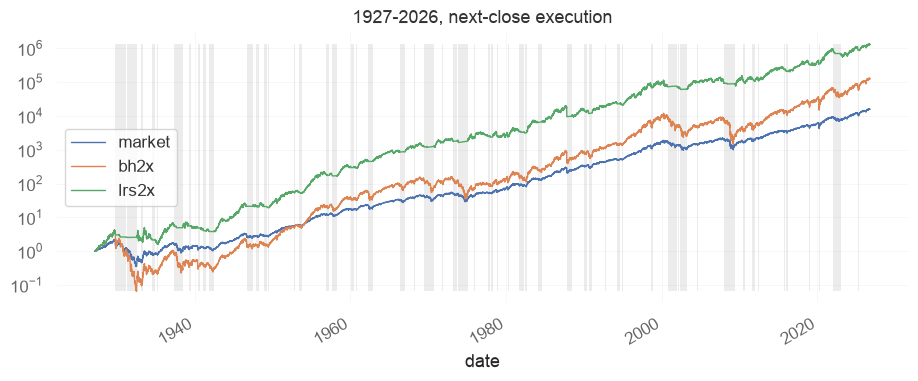

In [3]:
eq = (1 + s2[["market", "bh2x", "lrs2x"]]).cumprod()
ax = eq.plot(logy=True, lw=1)
off = s2.on == 0
ax.fill_between(s2.index, eq.min().min(), eq.max().max(), where=off, color="grey", alpha=.15, lw=0)
ax.set_title("1927-2026, next-close execution"); plt.show()

## 3. Drawdowns

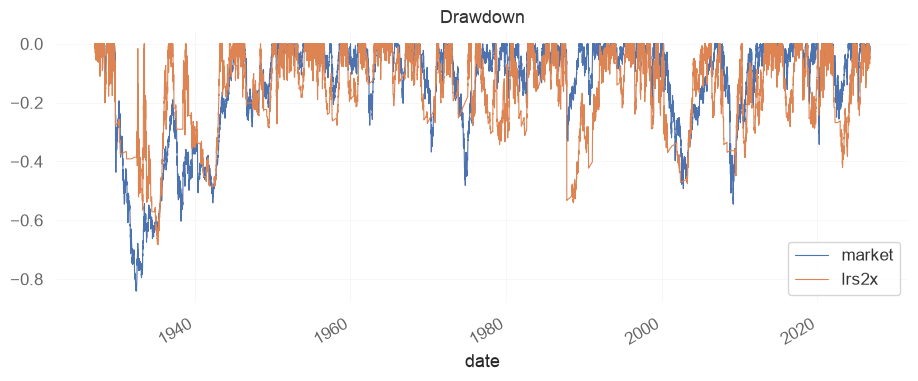

market    -84.1%
bh2x      -98.4%
lrs2x     -68.3%


In [4]:
dd = eq / eq.cummax() - 1
dd[["market", "lrs2x"]].plot(lw=.8, title="Drawdown"); plt.show()
print(dd.min().map("{:.1%}".format).to_string())

## 4. Rolling 10-year CAGR, LRS-2x minus market\nBelow zero = the rule trailed the index over that decade.

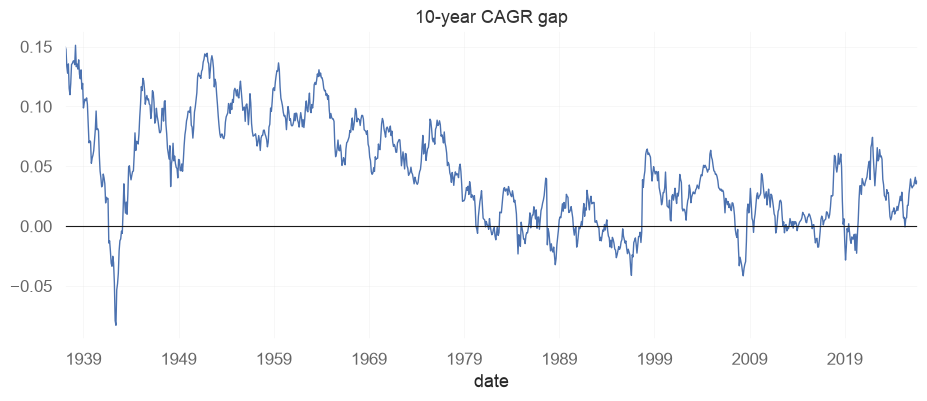

trails the market in 17% of rolling 10-year windows


In [5]:
m = (1 + s2[["market", "lrs2x"]]).resample("ME").prod()
r10 = m.rolling(120).apply(np.prod, raw=True) ** (1 / 10) - 1
gap = (r10.lrs2x - r10.market).dropna()
ax = gap.plot(lw=1, title="10-year CAGR gap"); ax.axhline(0, color="k", lw=.8); plt.show()
print(f"trails the market in {(gap < 0).mean():.0%} of rolling 10-year windows")

## 5. Deciding at 15:15 on the live price (SPY one-minute bars, 2016-2026)

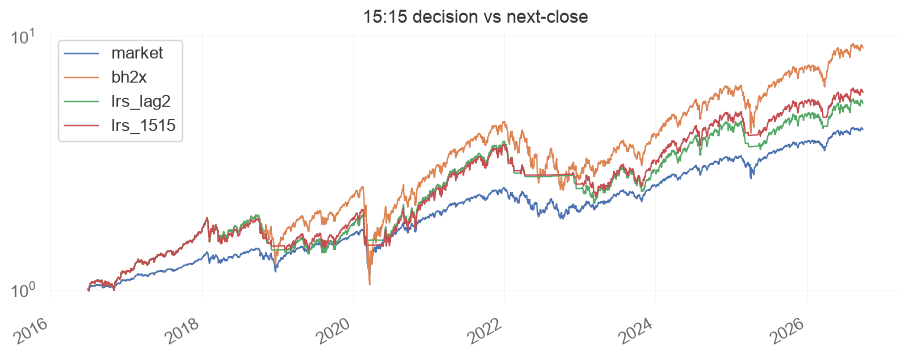

,cagr,sharpe,maxdd
market,0.152557,0.754007,-0.337173
bh2x,0.238799,0.714710,-0.589170
lrs_lag2,0.179607,0.712110,-0.430758
lrs_1515,0.190929,0.749146,-0.374453


In [6]:
s15 = M.run(M.daily())
eq15 = (1 + s15[["market", "bh2x", "lrs_lag2", "lrs_1515"]]).cumprod()
eq15.plot(logy=True, lw=1, title="15:15 decision vs next-close"); plt.show()
pd.DataFrame({c: L.perf(s15[c], s15.rf, s15.market) for c in eq15}).T[["cagr", "sharpe", "maxdd"]]

## 6. quantstats summary for the 15:15 rule vs SPY\nquantstats annualises by rows ÷ 252, which is right for SPY after 1952.

In [7]:
qs.reports.metrics(s15.lrs_1515, benchmark=s15.market, mode="basic", display=False)

,Benchmark,Strategy
Start Period,2016-07-01,2016-07-01
End Period,2026-09-30,2026-09-30
Risk-Free Rate,0,0
Time in Market,1.0,0.95
Cumulative Return,3.28,4.99
CAGR﹪,0.15,0.19
Sharpe,0.89,0.85
Prob. Sharpe Ratio,1.0,1.0
Sortino,1.26,1.16
Sortino/√2,0.89,0.82


## 7. Independent cross-check — must print 'All figures agree'

In [8]:
X.main()

repo / independent
  lag1 full     lrs1x    cagr +0.1088/+0.1088  maxdd -0.3403/-0.3403  sharpe +0.6830/+0.6830  alpha_t +4.1523/+4.1558  beta +0.4870/+0.4870
  lag1 full     lrs2x    cagr +0.1708/+0.1708  maxdd -0.6003/-0.6003  sharpe +0.6651/+0.6651  alpha_t +4.0692/+4.0726  beta +0.9785/+0.9785
  lag1 full     bh2x     cagr +0.1251/+0.1251  maxdd -0.9842/-0.9842  sharpe +0.4232/+0.4232  alpha_t -5.0008/-5.0050  beta +2.0242/+2.0242
  lag1 2016+    lrs2x    cagr +0.1872/+0.1872  maxdd -0.3524/-0.3524  sharpe +0.7281/+0.7281  alpha_t +0.4532/+0.4570  beta +1.2037/+1.2037
  lag2 full     lrs1x    cagr +0.1001/+0.1001  maxdd -0.4110/-0.4110  sharpe +0.6088/+0.6088  alpha_t +3.3750/+3.3779  beta +0.4667/+0.4667


  lag2 full     lrs2x    cagr +0.1519/+0.1519  maxdd -0.6830/-0.6830  sharpe +0.5911/+0.5911  alpha_t +3.3027/+3.3055  beta +0.9334/+0.9334
  lag2 full     bh2x     cagr +0.1252/+0.1252  maxdd -0.9842/-0.9842  sharpe +0.4233/+0.4233  alpha_t -5.0002/-5.0044  beta +2.0242/+2.0242
  lag2 2016+    lrs2x    cagr +0.1930/+0.1930  maxdd -0.4209/-0.4209  sharpe +0.7475/+0.7475  alpha_t +0.7386/+0.7447  beta +1.0929/+1.0929


  15:15 SPY     lrs_lag2 cagr +0.1796/+0.1796  maxdd -0.4308/-0.4308  sharpe +0.7121/+0.7121  alpha_t +0.3858/+0.3890  beta +1.1529/+1.1529
  15:15 SPY     lrs_1515 cagr +0.1909/+0.1909  maxdd -0.3745/-0.3745  sharpe +0.7491/+0.7491  alpha_t +0.5385/+0.5429  beta +1.2014/+1.2014

All figures agree within tolerance.


## 8. Today's signal (Yahoo closes; the live run uses the Robinhood quote at 15:15)

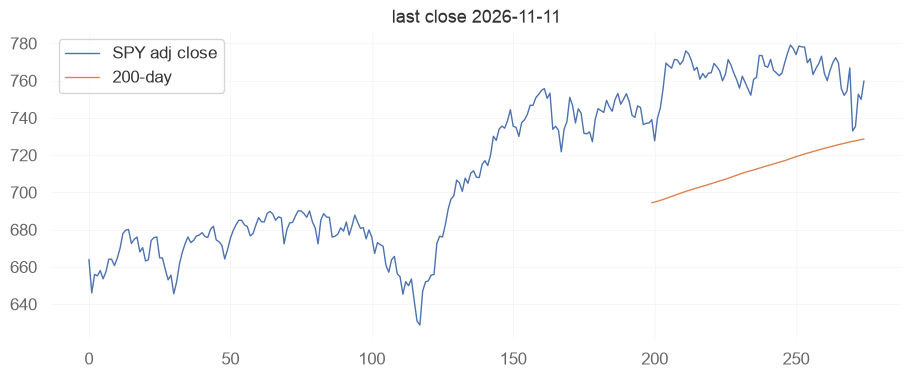

hold SSO | close 759.81 vs 200-day 728.65 | book status: manual


In [9]:
today = dt.datetime.now(lrs._ET).date()
closes, last = lrs.closes_before(today)
c = pd.Series(closes[-500:])
sma = c.rolling(200).mean()
ax = c.plot(lw=1, label="SPY adj close"); sma.plot(ax=ax, lw=1, label="200-day"); ax.legend()
ax.set_title(f"last close {last}"); plt.show()
print("hold", lrs.book()["vehicles"]["risk_on" if lrs.decide(closes) else "risk_off"],
      f"| close {closes[-1]:.2f} vs 200-day {sum(closes[-200:]) / 200:.2f}",
      "| book status:", lrs.book()["status"])